# 1. Project Introduction

# EuroSAT Land-Use and Land-Cover Classification

## Project Title

Reproducing a Deep Learning Baseline and Evaluating a Smaller Network

## Reference Paper

Helber, P., Bischke, B., Dengel, A., and Borth, D. (2019).  
*EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification.*  
IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing, 12(7), 2217–2226.

[https://doi.org/10.1109/JSTARS.2019.2918242](https://doi.org/10.1109/JSTARS.2019.2918242)

## Project Overview

This project investigates deep-learning-based land-use and land-cover classification using the EuroSAT RGB satellite image dataset.

The first objective is to reproduce the ResNet-50 baseline reported in the reference paper as closely as possible. After establishing the baseline, we will evaluate a smaller ResNet-18 network to investigate whether it can achieve comparable classification performance with lower computational cost.

## Objectives

1. Explore and verify the EuroSAT RGB dataset.
2. Reproduce the ResNet-50 baseline described in the reference paper.
3. Prepare reproducible training, validation, and test sets.
4. Train and evaluate ResNet-50 using the paper's reported training strategy.
5. Train and evaluate ResNet-18 under comparable experimental conditions.
6. Compare classification performance and computational cost.
7. Analyse classification errors and discuss the experimental results.

## Dataset Source

The primary dataset is the EuroSAT RGB archive published on Zenodo:

https://zenodo.org/records/7711810

The RGB dataset contains 27,000 labelled images across 10 land-use and land-cover classes. Each image has a spatial resolution of 64 × 64 pixels with three RGB channels.


# 2. Environment Setup

This section records the software environment used for the experiments and checks whether GPU acceleration is available.

Recording the software versions and hardware helps make the experiments easier to reproduce.


In [1]:
import os
import random
import platform
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
from PIL import Image

print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("NumPy version:", np.__version__)

# Check GPU availability
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    print("Running on CPU.")

print("Selected device:", DEVICE)


Python version: 3.13.16
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
NumPy version: 2.4.6
GPU available: True
GPU name: Tesla T4
Selected device: cuda


In [2]:
import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


# 3. Dataset Acquisition and Verification

## 3.1 Dataset Source

The EuroSAT RGB dataset is obtained from the official Zenodo record:

https://zenodo.org/records/7711810

The dataset contains 27,000 labelled satellite image patches belonging to 10 land-use and land-cover classes. Each image has a spatial resolution of 64 × 64 pixels with three RGB colour channels.


### 3.2 Dataset Download and Verification

We downloaded the dataset from Zenodo and verified its integrity using an MD5 checksum. The checksum matched the expected value, confirming that the downloaded archive passed the verification check.

In [3]:
import os
import hashlib
import shutil
import urllib.request
import zipfile
from pathlib import Path

# Official Zenodo EuroSAT RGB dataset
DATASET_URL = (
    "https://zenodo.org/api/records/7711810/"
    "files/EuroSAT_RGB.zip/content"
)

ZIP_PATH = Path("/content/EuroSAT_RGB.zip")
DATASET_DIR = Path("/content/EuroSAT_RGB")
TEMP_PATH = Path("/content/EuroSAT_RGB.zip.part")
EXTRACT_DIR = Path("/content/EuroSAT_extract")

EXPECTED_MD5 = "f46e308c4d50d4bf32fedad2d3d62f3b"
EXPECTED_TOTAL_IMAGES = 27000

EXPECTED_CLASSES = [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake",
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}


def calculate_md5(file_path):
    """Calculate the MD5 checksum of a file."""
    md5 = hashlib.md5()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            md5.update(chunk)

    return md5.hexdigest()


def count_images(folder):
    """Count images directly inside a class folder."""
    if not folder.is_dir():
        return 0

    return sum(
        1 for path in folder.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    )


def dataset_is_valid(root):
    """Check class folders and total image count."""
    if not root.is_dir():
        return False

    counts = {
        name: count_images(root / name)
        for name in EXPECTED_CLASSES
    }

    return (
        all(count > 0 for count in counts.values())
        and sum(counts.values()) == EXPECTED_TOTAL_IMAGES
    )


# Step 1: Verify or download the official Zenodo archive.
archive_valid = (
    ZIP_PATH.is_file()
    and calculate_md5(ZIP_PATH) == EXPECTED_MD5
)

if not archive_valid:
    print("Downloading official EuroSAT RGB from Zenodo...")

    try:
        request = urllib.request.Request(
            DATASET_URL,
            headers={"User-Agent": "EuroSAT-Project/1.0"}
        )

        with urllib.request.urlopen(
            request, timeout=180
        ) as response:
            print("HTTP status:", response.status)

            with open(TEMP_PATH, "wb") as file:
                while True:
                    chunk = response.read(1024 * 1024)
                    if not chunk:
                        break
                    file.write(chunk)

        actual_md5 = calculate_md5(TEMP_PATH)

        if actual_md5 != EXPECTED_MD5:
            raise ValueError(
                "Zenodo MD5 mismatch. "
                f"Expected {EXPECTED_MD5}, got {actual_md5}."
            )

        os.replace(TEMP_PATH, ZIP_PATH)
        print("Official Zenodo archive downloaded and verified.")

    finally:
        if TEMP_PATH.exists():
            TEMP_PATH.unlink()

else:
    print("Verified Zenodo archive already exists.")

# Verify archive integrity before extraction.
if calculate_md5(ZIP_PATH) != EXPECTED_MD5:
    raise ValueError("The Zenodo archive failed MD5 verification.")

if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError("The downloaded archive is not a valid ZIP file.")

print("Archive size:", round(ZIP_PATH.stat().st_size / 1_000_000, 2), "MB")
print("Verified MD5:", calculate_md5(ZIP_PATH))

# Step 2: Reuse a valid extracted dataset only after verifying the ZIP.
if dataset_is_valid(DATASET_DIR):
    print("Dataset folder is valid. Skipping extraction.")

else:
    print("Dataset folder missing or incomplete. Extracting Zenodo archive...")

    if EXTRACT_DIR.exists():
        shutil.rmtree(EXTRACT_DIR)

    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        # Prevent unexpected paths from escaping the extraction folder.
        base = EXTRACT_DIR.resolve()

        for member in archive.infolist():
            target = (EXTRACT_DIR / member.filename).resolve()

            if target != base and base not in target.parents:
                raise ValueError(
                    f"Unsafe archive path detected: {member.filename}"
                )

        archive.extractall(EXTRACT_DIR)

    # Locate the directory containing all expected class folders.
    candidates = [EXTRACT_DIR] + [
        path for path in EXTRACT_DIR.rglob("*")
        if path.is_dir()
    ]

    source_dir = next(
        (
            folder for folder in candidates
            if all(
                (folder / name).is_dir()
                for name in EXPECTED_CLASSES
            )
        ),
        None
    )

    if source_dir is None:
        raise RuntimeError(
            "Could not find all ten class folders after extraction."
        )

    # Replace any previous reconstructed dataset with the verified archive.
    if DATASET_DIR.exists():
        shutil.rmtree(DATASET_DIR)

    if source_dir == EXTRACT_DIR:
        # The class folders are directly inside the extraction directory.
        shutil.copytree(source_dir, DATASET_DIR)
    else:
        shutil.copytree(source_dir, DATASET_DIR)

    shutil.rmtree(EXTRACT_DIR)

# Step 3: Final dataset verification.
if not dataset_is_valid(DATASET_DIR):
    raise RuntimeError(
        "Extracted dataset verification failed. "
        "Expected 27,000 images across the ten classes."
    )

print("\nFINAL DATASET VERIFICATION")
print("-" * 40)

total_images = 0

for class_name in EXPECTED_CLASSES:
    count = count_images(DATASET_DIR / class_name)
    total_images += count
    print(f"{class_name}: {count:,}")

print("-" * 40)
print("Total images:", total_images)
print("Number of classes:", len(EXPECTED_CLASSES))
print("Dataset directory:", DATASET_DIR)
print("Source: Official Zenodo EuroSAT RGB archive")

assert total_images == EXPECTED_TOTAL_IMAGES
assert dataset_is_valid(DATASET_DIR)

print("\nAll dataset checks passed!")


HTTP status: 200
Official Zenodo archive downloaded and verified.
Archive size: 94.66 MB
Verified MD5: f46e308c4d50d4bf32fedad2d3d62f3b
Dataset folder missing or incomplete. Extracting Zenodo archive...

FINAL DATASET VERIFICATION
----------------------------------------
AnnualCrop: 3,000
Forest: 3,000
HerbaceousVegetation: 3,000
Highway: 2,500
Industrial: 2,500
Pasture: 2,000
PermanentCrop: 2,500
Residential: 3,000
River: 2,500
SeaLake: 3,000
----------------------------------------
Total images: 27000
Number of classes: 10
Dataset directory: /content/EuroSAT_RGB
Source: Official Zenodo EuroSAT RGB archive

All dataset checks passed!



# 4. Dataset Exploration

In this section, we explore the EuroSAT RGB dataset to understand its class distribution, image characteristics, and visual differences between land-use and land-cover categories.

We display the image counts for each class and examine representative sample images before preparing the dataset for model training.

The dataset contains 27,000 images across 10 classes, with each image measuring 64 × 64 pixels and containing three RGB channels.

The dataset is released under the MIT licence.

We also consider dataset limitations reported in the reference paper, including colour casts caused by the lack of atmospheric correction and image patches containing clouds or possible mislabelling. These limitations will be revisited during the model's error analysis.



### 4.1 Inspecting Sample Images

We selected three representative images from each of the 10 classes to examine their visual characteristics and differences. We also checked the image dimensions and colour mode to understand how the satellite images are represented in the dataset.


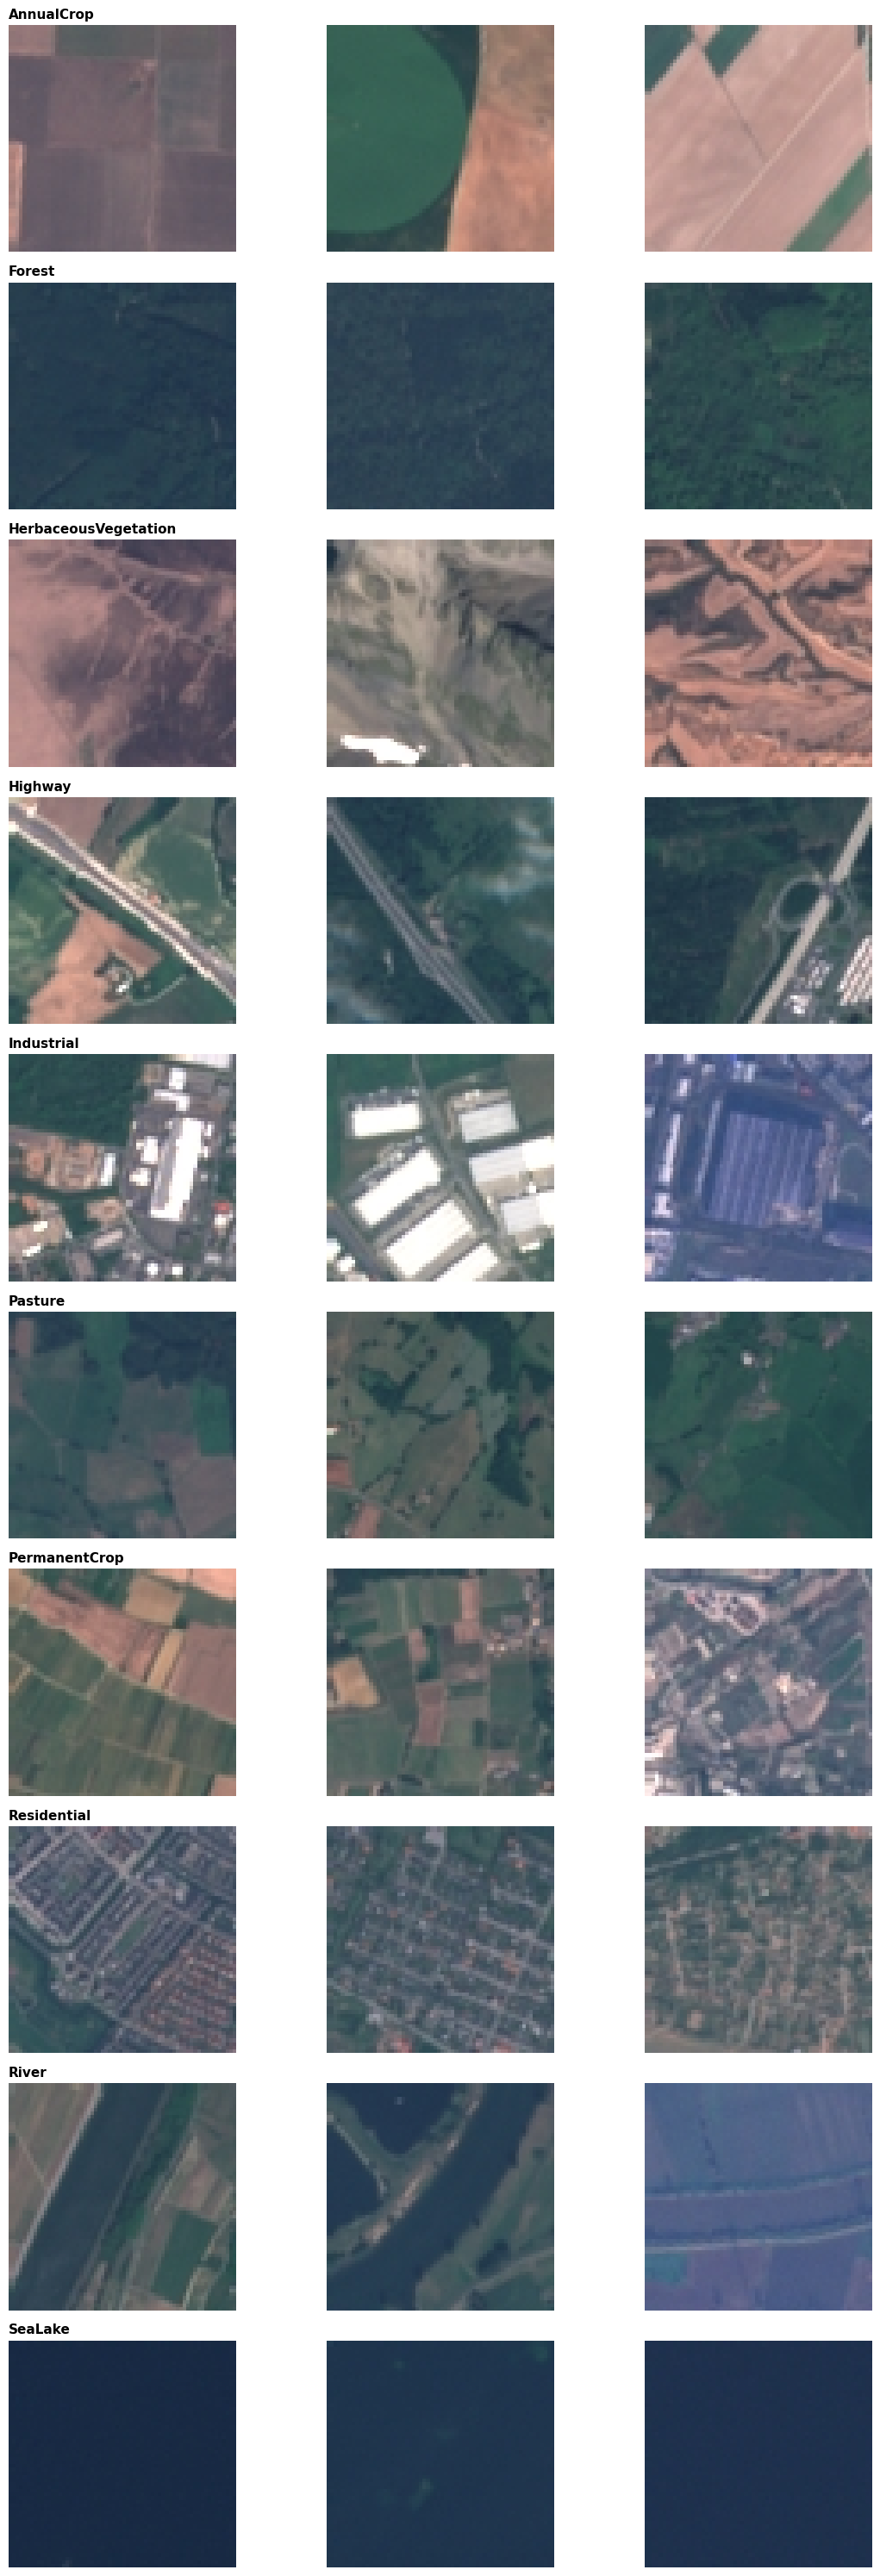

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Display three sample images from each class
class_names = sorted(EXPECTED_CLASSES)

fig, axes = plt.subplots(
    nrows=len(class_names),
    ncols=3,
    figsize=(12, 30)
)

for row, class_name in enumerate(class_names):

    class_path = os.path.join(DATASET_DIR, class_name)

    image_files = sorted([
        file_name
        for file_name in os.listdir(class_path)
        if file_name.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    # Select three sample images
    sample_images = image_files[:3]

    for col, file_name in enumerate(sample_images):

        image_path = os.path.join(class_path, file_name)

        with Image.open(image_path) as image:
            axes[row, col].imshow(image.convert("RGB"))

        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(
                class_name,
                loc="left",
                fontsize=11,
                fontweight="bold"
            )

plt.tight_layout()
plt.show()

### 4.2 Class Distribution

We visualised the number of images in each land-use and land-cover class using a bar chart. This provides an overview of the class distribution and helps us understand whether the dataset is balanced.

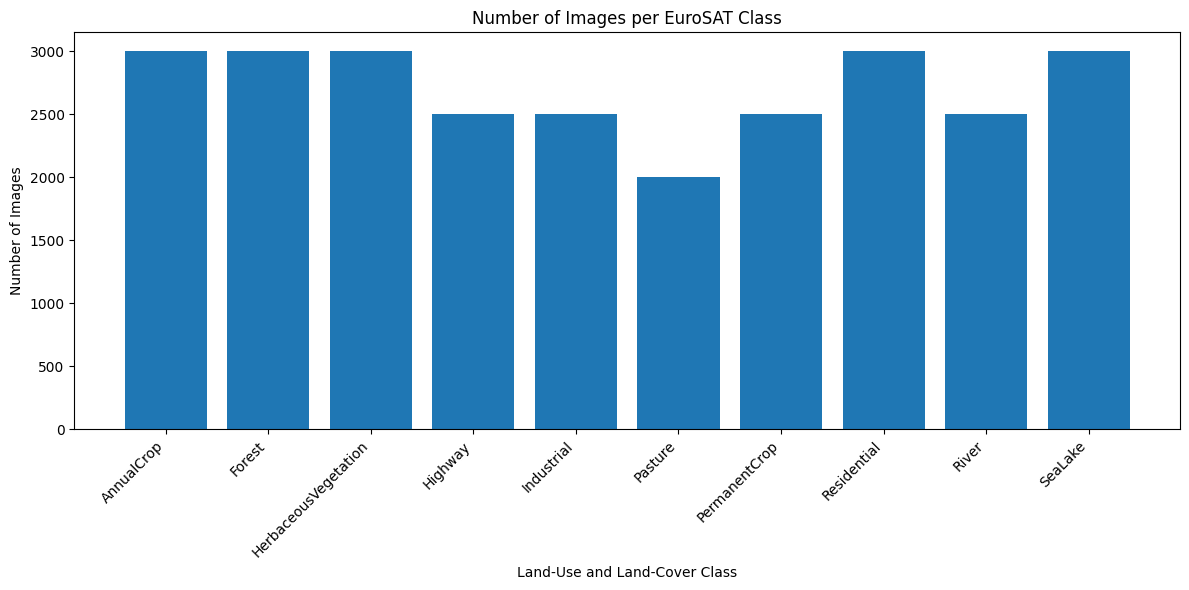

In [5]:
from collections import Counter

# Count images in each class
class_counts = {}

for class_name in sorted(EXPECTED_CLASSES):
    class_path = os.path.join(DATASET_DIR, class_name)

    image_files = [
        file_name
        for file_name in os.listdir(class_path)
        if file_name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    class_counts[class_name] = len(image_files)

# Plot class distribution
plt.figure(figsize=(12, 6))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Number of Images per EuroSAT Class")
plt.xlabel("Land-Use and Land-Cover Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### 4.3 Checking Image Data Quality

We checked whether the image files could be opened successfully and whether they had the expected RGB format and image dimensions. This helped us identify any unreadable or incorrectly formatted images before training our models.

In [6]:
unreadable_images = []
unexpected_images = []

for class_name in sorted(EXPECTED_CLASSES):
    class_path = os.path.join(DATASET_DIR, class_name)

    for file_name in os.listdir(class_path):
        if not file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        image_path = os.path.join(class_path, file_name)

        try:
            with Image.open(image_path) as image:
                image.verify()

            with Image.open(image_path) as image:
                if image.size != (64, 64) or image.mode != "RGB":
                    unexpected_images.append(
                        (image_path, image.size, image.mode)
                    )

        except Exception:
            unreadable_images.append(image_path)

print("Unreadable images:", len(unreadable_images))
print("Images with unexpected dimensions or colour mode:",
      len(unexpected_images))

if unreadable_images:
    print("Examples of unreadable images:", unreadable_images[:5])

if unexpected_images:
    print("Examples of unexpected images:", unexpected_images[:5])


Unreadable images: 0
Images with unexpected dimensions or colour mode: 0


### 4.4 Inspecting Image Properties

We examined the dimensions, colour mode, and pixel values of a sample image to better understand how the satellite images are represented before preprocessing.

In [7]:
sample_class = "AnnualCrop"
sample_folder = os.path.join(DATASET_DIR, sample_class)

sample_files = sorted([
    file_name
    for file_name in os.listdir(sample_folder)
    if file_name.lower().endswith((".jpg", ".jpeg", ".png"))
])

sample_path = os.path.join(sample_folder, sample_files[0])

with Image.open(sample_path) as image:
    sample_image = image.convert("RGB")
    image_array = np.array(sample_image)

print("Sample image:", sample_files[0])
print("Image dimensions:", sample_image.size)
print("Colour mode:", sample_image.mode)
print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())


Sample image: AnnualCrop_1.jpg
Image dimensions: (64, 64)
Colour mode: RGB
Array shape: (64, 64, 3)
Data type: uint8
Minimum pixel value: 82
Maximum pixel value: 204


### 4.5 Checking for Duplicate Images

We checked the dataset for exact duplicate image files using their MD5 hashes. This helped us identify whether identical files were present under different filenames.

In [8]:
import hashlib
from collections import defaultdict

image_hashes = defaultdict(list)

for class_name in sorted(EXPECTED_CLASSES):
    class_path = os.path.join(DATASET_DIR, class_name)

    for file_name in os.listdir(class_path):
        if not file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        image_path = os.path.join(class_path, file_name)

        with open(image_path, "rb") as file:
            file_hash = hashlib.md5(file.read()).hexdigest()

        image_hashes[file_hash].append((class_name, file_name))

duplicate_groups = [
    files for files in image_hashes.values()
    if len(files) > 1
]

duplicate_file_count = sum(
    len(files) - 1 for files in duplicate_groups
)

print("Total image files checked:", sum(class_counts.values()))
print("Duplicate groups found:", len(duplicate_groups))
print("Extra duplicate files:", duplicate_file_count)

if duplicate_groups:
    print("\nExamples of duplicates:")
    for group in duplicate_groups[:10]:
        print(group)
else:
    print("No exact duplicate files found.")


Total image files checked: 27000
Duplicate groups found: 0
Extra duplicate files: 0
No exact duplicate files found.


### 4.6 Dataset-Wide Pixel and Missing-Value Checks

We checked the pixel-value range and missing pixel values across all readable images. We also verified that every image has a valid class label from its folder name.

In [9]:
pixel_min = []
pixel_max = []
missing_pixels = 0
checked_images = 0

# Check whether the dataset contains only the expected class folders
actual_classes = {
    name for name in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, name))
}

invalid_labels = actual_classes - set(EXPECTED_CLASSES)

for class_name in sorted(EXPECTED_CLASSES):
    class_path = os.path.join(DATASET_DIR, class_name)

    for file_name in os.listdir(class_path):
        if not file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        image_path = os.path.join(class_path, file_name)

        with Image.open(image_path) as image:
            pixels = np.array(image.convert("RGB"))

        pixel_min.append(pixels.min())
        pixel_max.append(pixels.max())
        missing_pixels += np.isnan(pixels).sum()
        checked_images += 1

print("Images checked:", checked_images)
print("Dataset-wide minimum pixel value:", min(pixel_min))
print("Dataset-wide maximum pixel value:", max(pixel_max))
print("Missing pixel values:", missing_pixels)
print("Unexpected class folders:", invalid_labels)

assert checked_images == 27000
assert len(invalid_labels) == 0
assert missing_pixels == 0

print("\nDataset-wide checks passed!")

Images checked: 27000
Dataset-wide minimum pixel value: 0
Dataset-wide maximum pixel value: 255
Missing pixel values: 0
Unexpected class folders: set()

Dataset-wide checks passed!


# 5. Data Preparation

After exploring the dataset and checking its quality, we prepared the image paths and corresponding class labels for model training.

We divided the dataset into training, validation, and test sets using a stratified split to preserve the class distribution.

Following the reference paper, 80% of the images are reserved for training and validation, while 20% are held out for testing. The validation set is derived from the training portion and is used for model selection and tuning.

The test set is kept separate and is used for final evaluation after model development.

### 5.1 Collecting Image Paths and Labels

We collected the paths of all images along with their corresponding class labels. These labels will be used as the target values during model training.

In [10]:
image_paths = []
image_labels = []

for class_name in sorted(EXPECTED_CLASSES):
    class_path = os.path.join(DATASET_DIR, class_name)

    for file_name in sorted(os.listdir(class_path)):
        if file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(class_path, file_name))
            image_labels.append(class_name)

print("Total image paths:", len(image_paths))
print("Total labels:", len(image_labels))
print("First image path:", image_paths[0])
print("First image label:", image_labels[0])


Total image paths: 27000
Total labels: 27000
First image path: /content/EuroSAT_RGB/AnnualCrop/AnnualCrop_1.jpg
First image label: AnnualCrop


# 5. Data Preparation

After exploring the dataset and checking its quality, we prepared the image paths and corresponding class labels for model training.

We divided the dataset into training, validation, and test sets using a stratified split to preserve the class distribution.

Following the reference paper, 80% of the images are reserved for training and validation, while 20% are held out for testing. The validation set is derived from the training portion and is used for model selection and tuning.

The test set is kept separate and is used for final evaluation after model development.

### 5.1 Collecting Image Paths and Labels

We collected the paths of all images along with their corresponding class labels. These labels will be used as the target values during model training.

In [11]:
image_paths = []
image_labels = []

for class_name in sorted(EXPECTED_CLASSES):
    class_path = os.path.join(DATASET_DIR, class_name)

    for file_name in sorted(os.listdir(class_path)):
        if file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(class_path, file_name))
            image_labels.append(class_name)

print("Total image paths:", len(image_paths))
print("Total labels:", len(image_labels))
print("First image path:", image_paths[0])
print("First image label:", image_labels[0])

Total image paths: 27000
Total labels: 27000
First image path: /content/EuroSAT_RGB/AnnualCrop/AnnualCrop_1.jpg
First image label: AnnualCrop


### 5.2 Splitting the Dataset

We divided the 27,000 EuroSAT images into training, validation, and test sets using stratified sampling. This approach preserves the proportion of each land-use and land-cover class across all three sets.

- **Training set (72%):** 19,440 images used to train the models.
- **Validation set (8%):** 2,160 images used to monitor model performance and guide model selection.
- **Test set (20%):** 5,400 images reserved for final evaluation.

The training and validation sets together account for 80% of the dataset, following the train/test split used in the reference paper. The validation set is derived from the 80% training portion.

We use a fixed random seed of 42 to make the split reproducible. Both ResNet-50 and ResNet-18 will use the same split to ensure a fair comparison.

#### Split Integrity and Class Distribution Checks

After splitting the dataset, we verify the sizes of all three sets and check for overlapping image paths. We confirm that no images are shared between the training, validation, and test sets and that all 27,000 images are accounted for.

We also examine the class distribution in each split to confirm that stratified sampling preserves the expected class proportions.

In [12]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Fixed random seed for reproducibility
RANDOM_SEED = 42

# --------------------------------------------------
# Step 1: Split the dataset into 80% train/validation
#         and 20% test sets
# --------------------------------------------------

X_train_val, X_test, y_train_val, y_test = train_test_split(
    image_paths,
    image_labels,
    test_size=0.20,              # 20% reserved for testing
    random_state=RANDOM_SEED,
    stratify=image_labels        # Preserve class proportions
)

# --------------------------------------------------
# Step 2: Split the remaining 80% into training
#         and validation sets
# --------------------------------------------------

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.10,              # 10% of 80% = 8% of full dataset
    random_state=RANDOM_SEED,
    stratify=y_train_val         # Preserve class proportions
)

# --------------------------------------------------
# Step 3: Display and verify split sizes
# --------------------------------------------------

print("DATASET SPLIT SIZES")
print("-" * 35)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))
print("Total images:", len(X_train) + len(X_val) + len(X_test))

# Verify the expected split sizes
assert len(X_train) == 19440
assert len(X_val) == 2160
assert len(X_test) == 5400

# --------------------------------------------------
# Step 4: Check for overlap between dataset splits
# --------------------------------------------------

train_paths = set(X_train)
val_paths = set(X_val)
test_paths = set(X_test)

# Combine all paths to verify that every image is accounted for
all_split_paths = train_paths | val_paths | test_paths

print("\nSPLIT INTEGRITY CHECKS")
print("-" * 35)

print("Train/validation overlap:", len(train_paths & val_paths))
print("Train/test overlap:", len(train_paths & test_paths))
print("Validation/test overlap:", len(val_paths & test_paths))
print("Unique image paths:", len(all_split_paths))

# Verify that there are no overlapping images
assert not (train_paths & val_paths)
assert not (train_paths & test_paths)
assert not (val_paths & test_paths)

# Verify that all 27,000 images are accounted for
assert len(all_split_paths) == 27000

# --------------------------------------------------
# Step 5: Display class distribution across splits
# --------------------------------------------------

# Combine the class labels and their corresponding split names
split_labels = pd.DataFrame({
    "class_name": (
        y_train
        + y_val
        + y_test
    ),
    "split": (
        ["train"] * len(y_train)
        + ["validation"] * len(y_val)
        + ["test"] * len(y_test)
    )
})

# Create a table showing the number of images per class in each split
class_distribution = pd.crosstab(
    split_labels["class_name"],
    split_labels["split"]
)

# Arrange the columns in the correct order
class_distribution = class_distribution[
    ["train", "validation", "test"]
]

print("\nCLASS DISTRIBUTION")
print("-" * 35)
print(class_distribution)

# --------------------------------------------------
# Step 6: Confirm that all checks passed
# --------------------------------------------------

print("\nAll dataset splitting and integrity checks passed!")

DATASET SPLIT SIZES
-----------------------------------
Training images: 19440
Validation images: 2160
Test images: 5400
Total images: 27000

SPLIT INTEGRITY CHECKS
-----------------------------------
Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0
Unique image paths: 27000

CLASS DISTRIBUTION
-----------------------------------
split                 train  validation  test
class_name                                   
AnnualCrop             2160         240   600
Forest                 2160         240   600
HerbaceousVegetation   2160         240   600
Highway                1800         200   500
Industrial             1800         200   500
Pasture                1440         160   400
PermanentCrop          1800         200   500
Residential            2160         240   600
River                  1800         200   500
SeaLake                2160         240   600

All dataset splitting and integrity checks passed!


### 5.3 Saving the Dataset Splits and Class Mapping

We saved the dataset split assignments in a CSV file containing each image's relative path, class name, numerical class index, and split assignment. We also saved the class-to-index mapping in a JSON file.

Saving these files allows us to reuse the same data splits and consistent class labels across both models, supporting reproducibility and a fair comparison.

In [13]:
import os
import json
import pandas as pd

# Create a consistent mapping of class names to numerical indices
class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(sorted(EXPECTED_CLASSES))
}

# Collect image paths, labels, and split assignments
records = []

split_data = [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test)
]

for split_name, paths, labels in split_data:
    for path, label in zip(paths, labels):
        # Save a relative path instead of a Colab-specific absolute path
        relative_path = os.path.relpath(path, DATASET_DIR)

        records.append({
            "relative_path": relative_path,
            "class_name": label,
            "class_idx": class_to_idx[label],
            "split": split_name
        })

# Save the split assignments
splits_df = pd.DataFrame(records)
splits_df.to_csv("/content/eurosat_splits.csv", index=False)

# Save the class-to-index mapping
with open("/content/class_to_idx.json", "w") as file:
    json.dump(class_to_idx, file, indent=2)

# Display a summary
print("Split assignments saved to: /content/eurosat_splits.csv")
print("Class mapping saved to: /content/class_to_idx.json")

print("\nNumber of records:", len(splits_df))
print("\nImages per split:")
print(splits_df["split"].value_counts())

print("\nClass-to-index mapping:")
print(class_to_idx)

print("\nFirst five records:")
print(splits_df.head())


Split assignments saved to: /content/eurosat_splits.csv
Class mapping saved to: /content/class_to_idx.json

Number of records: 27000

Images per split:
split
train         19440
test           5400
validation     2160
Name: count, dtype: int64

Class-to-index mapping:
{'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}

First five records:
                    relative_path  class_name  class_idx  split
0  Industrial/Industrial_1389.jpg  Industrial          4  train
1          Forest/Forest_2296.jpg      Forest          1  train
2         Highway/Highway_274.jpg     Highway          3  train
3   Industrial/Industrial_622.jpg  Industrial          4  train
4  AnnualCrop/AnnualCrop_1129.jpg  AnnualCrop          0  train


### 5.4 Preparing Images for Model Training

Before training the deep learning models, we prepared the data-loading pipeline in PyTorch. We reused the saved dataset split assignments and class-to-index mapping to maintain consistent image assignments and labels throughout the experiments.

In [14]:
import os
import json
import pandas as pd

# Load the saved dataset split assignments
splits_df = pd.read_csv("/content/eurosat_splits.csv")

# Load the saved class-to-index mapping
with open("/content/class_to_idx.json", "r") as file:
    class_to_idx = json.load(file)

# Define the dataset directory
DATASET_DIR = "/content/EuroSAT_RGB"

# --------------------------------------------------
# Step 1: Display the saved split information
# --------------------------------------------------

print("Total saved records:", len(splits_df))

print("\nImages per split:")
print(splits_df["split"].value_counts())

print("\nNumber of classes:", len(class_to_idx))

print("\nClass mapping:")
print(class_to_idx)

# --------------------------------------------------
# Step 2: Verify the expected split sizes
# --------------------------------------------------

expected_split_counts = {
    "train": 19440,
    "validation": 2160,
    "test": 5400
}

actual_split_counts = splits_df["split"].value_counts().to_dict()

assert len(splits_df) == 27000
assert actual_split_counts == expected_split_counts
assert len(class_to_idx) == 10

# --------------------------------------------------
# Step 3: Verify that all saved image paths exist
# --------------------------------------------------

image_paths_exist = splits_df["relative_path"].apply(
    lambda path: os.path.isfile(
        os.path.join(DATASET_DIR, path)
    )
)

assert image_paths_exist.all()

# --------------------------------------------------
# Step 4: Confirm successful loading and verification
# --------------------------------------------------

print("\nAll saved image paths exist:", image_paths_exist.all())

print("\nSaved split information loaded and verified successfully!")

Total saved records: 27000

Images per split:
split
train         19440
test           5400
validation     2160
Name: count, dtype: int64

Number of classes: 10

Class mapping:
{'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}

All saved image paths exist: True

Saved split information loaded and verified successfully!


#### 5.4.1 Image Preprocessing and Data Loading

We used PyTorch to load the EuroSAT images and their corresponding numerical labels. Each image was converted into a tensor and normalized using the ImageNet channel means and standard deviations, which are appropriate for our pretrained ResNet models.

We retained the original image resolution of 64 × 64 pixels. The images were then organized into batches using PyTorch DataLoaders. The training loader shuffles the training images, while the validation and test loaders preserve their order.

In [20]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# ImageNet normalization values for pretrained ResNet models
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Convert images to tensors and normalize them
# image_transform = transforms.Compose([
#     transforms.ToTensor(),
#     transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
# ])
image_transform = transforms.Compose([
    transforms.Resize((224, 224), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std
    )
])

# Define a custom EuroSAT dataset
class EuroSATDataset(Dataset):
    def __init__(self, dataframe, root_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = os.path.join(
            self.root_dir,
            row["relative_path"]
        )

        # Load the image and ensure it has three RGB channels
        image = Image.open(image_path).convert("RGB")

        # Apply preprocessing
        if self.transform is not None:
            image = self.transform(image)

        # Retrieve the numerical class label
        label = int(row["class_idx"])

        return image, label


# Separate the saved records into their existing splits
train_df = splits_df[splits_df["split"] == "train"]
val_df = splits_df[splits_df["split"] == "validation"]
test_df = splits_df[splits_df["split"] == "test"]

# Create dataset objects
train_dataset = EuroSATDataset(
    train_df, DATASET_DIR, image_transform
)
val_dataset = EuroSATDataset(
    val_df, DATASET_DIR, image_transform
)
test_dataset = EuroSATDataset(
    test_df, DATASET_DIR, image_transform
)

# Set the batch size
BATCH_SIZE = 64

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Verify the datasets and inspect one batch
print("DATASET SIZES")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

images, labels = next(iter(train_loader))

print("\nFIRST TRAINING BATCH")
print("Image tensor shape:", images.shape)
print("Label tensor shape:", labels.shape)
print("Image tensor data type:", images.dtype)
print("Label tensor data type:", labels.dtype)
print("Minimum normalized value:", images.min().item())
print("Maximum normalized value:", images.max().item())

print("\nPyTorch datasets and DataLoaders created successfully.")


DATASET SIZES
Training: 19440
Validation: 2160
Test: 5400

FIRST TRAINING BATCH
Image tensor shape: torch.Size([64, 3, 224, 224])
Label tensor shape: torch.Size([64])
Image tensor data type: torch.float32
Label tensor data type: torch.int64
Minimum normalized value: -1.7754088640213013
Maximum normalized value: 2.640000104904175

PyTorch datasets and DataLoaders created successfully.


In [21]:
from google.colab import drive
from pathlib import Path
from datetime import datetime

drive.mount("/content/drive")

# A separate folder prevents overwriting earlier experiments.
RESULTS_DIR = (
    Path("/content/drive/MyDrive/EuroSAT/results")
    / f"resnet50_64_full80_{datetime.now():%Y%m%d_%H%M%S}"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Saving results to:", RESULTS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving results to: /content/drive/MyDrive/EuroSAT/results/resnet50_64_full80_20261103_162827


In [22]:
import json
import random
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from torchvision import transforms

SEED = 42
BATCH_SIZE = 64
HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 15
HEAD_LR = 0.01
FINETUNE_LR = 0.0001
WEIGHT_DECAY = 1e-4

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    print("WARNING: GPU is not available. Training will proceed on CPU, which may be very slow.")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Original 64 × 64 images: no resize and no new augmentation.
image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Combine the EXISTING training and validation assignments.
full_train_df = splits_df[
    splits_df["split"].isin(["train", "validation"])
].copy()

test_df = splits_df[splits_df["split"] == "test"].copy()

assert len(full_train_df) == 21600
assert len(test_df) == 5400
assert splits_df["relative_path"].is_unique
assert set(full_train_df["relative_path"]).isdisjoint(
    set(test_df["relative_path"])
)

full_train_dataset = EuroSATDataset(
    full_train_df, DATASET_DIR, image_transform
)
test_dataset = EuroSATDataset(
    test_df, DATASET_DIR, image_transform
)

full_train_loader = DataLoader(
    full_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Preserve original assignments and the actual full-80% assignments.
splits_df.to_csv(RESULTS_DIR / "eurosat_splits.csv", index=False)

full80_splits = splits_df.copy()
full80_splits.loc[
    full80_splits["split"].isin(["train", "validation"]), "split"
] = "train"
full80_splits.to_csv(
    RESULTS_DIR / "eurosat_splits_full80.csv", index=False
)

with open(RESULTS_DIR / "class_to_idx.json", "w") as f:
    json.dump(class_to_idx, f, indent=2)

print("Training images:", len(full_train_dataset))
print("Test images:", len(test_dataset))
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU.")

Training images: 21600
Test images: 5400
GPU: Tesla T4


train a fesh resnet50


In [23]:
import time
import torchvision
import torch.nn as nn
from torchvision import models

# Reset randomness immediately before model construction.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

model = models.resnet50(
    weights=models.ResNet50_Weights.IMAGENET1K_V2
)
model.fc = nn.Linear(model.fc.in_features, len(class_to_idx))
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

config = {
    "architecture": "resnet50",
    "weights": "IMAGENET1K_V2",
    "seed": SEED,
    "image_size": 64,
    "training_images": len(full_train_dataset),
    "test_images": len(test_dataset),
    "batch_size": BATCH_SIZE,
    "head_epochs": HEAD_EPOCHS,
    "finetune_epochs": FINETUNE_EPOCHS,
    "head_lr": HEAD_LR,
    "finetune_lr": FINETUNE_LR,
    "optimizer": "AdamW",
    "weight_decay": WEIGHT_DECAY,
    "checkpoint_rule": "final epoch; duration fixed before test evaluation",
    "duration_reason": "64px validation run: best overall epoch 18",
    "gpu": torch.cuda.get_device_name(0),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "parameters": sum(p.numel() for p in model.parameters())
}

with open(RESULTS_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

history = []
global_epoch = 0

torch.cuda.synchronize()
start = time.perf_counter()

for stage, epochs, lr in [
    ("head_training", HEAD_EPOCHS, HEAD_LR),
    ("fine_tuning", FINETUNE_EPOCHS, FINETUNE_LR)
]:
    head_only = stage == "head_training"

    for parameter in model.parameters():
        parameter.requires_grad = not head_only

    for parameter in model.fc.parameters():
        parameter.requires_grad = True

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        weight_decay=WEIGHT_DECAY
    )

    for stage_epoch in range(1, epochs + 1):
        global_epoch += 1

        if head_only:
            # Keep backbone BatchNorm statistics frozen.
            model.eval()
            model.fc.train()
        else:
            model.train()

        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        for images, labels in full_train_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            count = labels.size(0)
            total_loss += loss.item() * count
            total_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            total_samples += count

        torch.cuda.synchronize()
        elapsed = (time.perf_counter() - start) / 60

        row = {
            "seed": SEED,
            "epoch": global_epoch,
            "stage": stage,
            "stage_epoch": stage_epoch,
            "train_loss": total_loss / total_samples,
            "train_accuracy": total_correct / total_samples,
            "elapsed_minutes": elapsed
        }
        history.append(row)

        pd.DataFrame(history).to_csv(
            RESULTS_DIR / "training_history.csv", index=False
        )

        # Save to a temporary file, then replace the last checkpoint.
        temporary_path = RESULTS_DIR / "checkpoint.tmp"
        torch.save({
            "state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": global_epoch,
            "stage": stage,
            "stage_epoch": stage_epoch,
            "config": config,
            "class_to_idx": class_to_idx
        }, temporary_path)
        temporary_path.replace(
            RESULTS_DIR / f"resnet50_seed_{SEED}.pth"
        )

        print(
            f"{stage} | {stage_epoch}/{epochs} | "
            f"Train loss: {row['train_loss']:.4f} | "
            f"Train accuracy: {row['train_accuracy']:.4f} | "
            f"Elapsed: {elapsed:.2f} min"
        )

print("\nTraining completed and saved to Drive.")
print("Final overall epoch:", global_epoch)
print("Results:", RESULTS_DIR)

head_training | 1/3 | Train loss: 0.5303 | Train accuracy: 0.8813 | Elapsed: 0.36 min
head_training | 2/3 | Train loss: 0.2904 | Train accuracy: 0.9336 | Elapsed: 0.72 min
head_training | 3/3 | Train loss: 0.2170 | Train accuracy: 0.9477 | Elapsed: 1.02 min
fine_tuning | 1/15 | Train loss: 0.4320 | Train accuracy: 0.8812 | Elapsed: 1.57 min
fine_tuning | 2/15 | Train loss: 0.0704 | Train accuracy: 0.9776 | Elapsed: 2.16 min
fine_tuning | 3/15 | Train loss: 0.0344 | Train accuracy: 0.9881 | Elapsed: 2.82 min
fine_tuning | 4/15 | Train loss: 0.0255 | Train accuracy: 0.9918 | Elapsed: 3.40 min
fine_tuning | 5/15 | Train loss: 0.0219 | Train accuracy: 0.9933 | Elapsed: 3.98 min
fine_tuning | 6/15 | Train loss: 0.0177 | Train accuracy: 0.9951 | Elapsed: 4.57 min
fine_tuning | 7/15 | Train loss: 0.0151 | Train accuracy: 0.9948 | Elapsed: 5.15 min
fine_tuning | 8/15 | Train loss: 0.0179 | Train accuracy: 0.9945 | Elapsed: 5.74 min
fine_tuning | 9/15 | Train loss: 0.0147 | Train accuracy: 0.99

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

model.eval()
true_labels = []
predicted_labels = []

with torch.inference_mode():
    for images, labels in test_loader:
        logits = model(images.to(DEVICE, non_blocking=True))
        predicted_labels.extend(logits.argmax(dim=1).cpu().tolist())
        true_labels.extend(labels.tolist())

precision, recall, f1, _ = precision_recall_fscore_support(
    true_labels,
    predicted_labels,
    average="macro",
    zero_division=0
)
accuracy = accuracy_score(true_labels, predicted_labels)

results = pd.DataFrame([{
    "seed": SEED,
    "test_accuracy": accuracy,
    "test_precision": precision,
    "test_recall": recall,
    "test_f1_score": f1
}])
results.to_csv(RESULTS_DIR / "test_results.csv", index=False)

predictions = test_df[
    ["relative_path", "class_name", "class_idx"]
].reset_index(drop=True)
predictions["predicted_class_idx"] = predicted_labels
predictions.to_csv(
    RESULTS_DIR / "test_predictions.csv", index=False
)

display(results)
print(f"Test accuracy: {accuracy * 100:.2f}%")
print(f"Gap to paper: {98.57 - accuracy * 100:+.2f} percentage points")
print("All results saved to:", RESULTS_DIR)

,seed,test_accuracy,test_precision,test_recall,test_f1_score
0,42,0.970185,0.969461,0.96915,0.969198


Test accuracy: 97.02%
Gap to paper: +1.55 percentage points
All results saved to: /content/drive/MyDrive/EuroSAT/results/resnet50_64_full80_20261103_162827


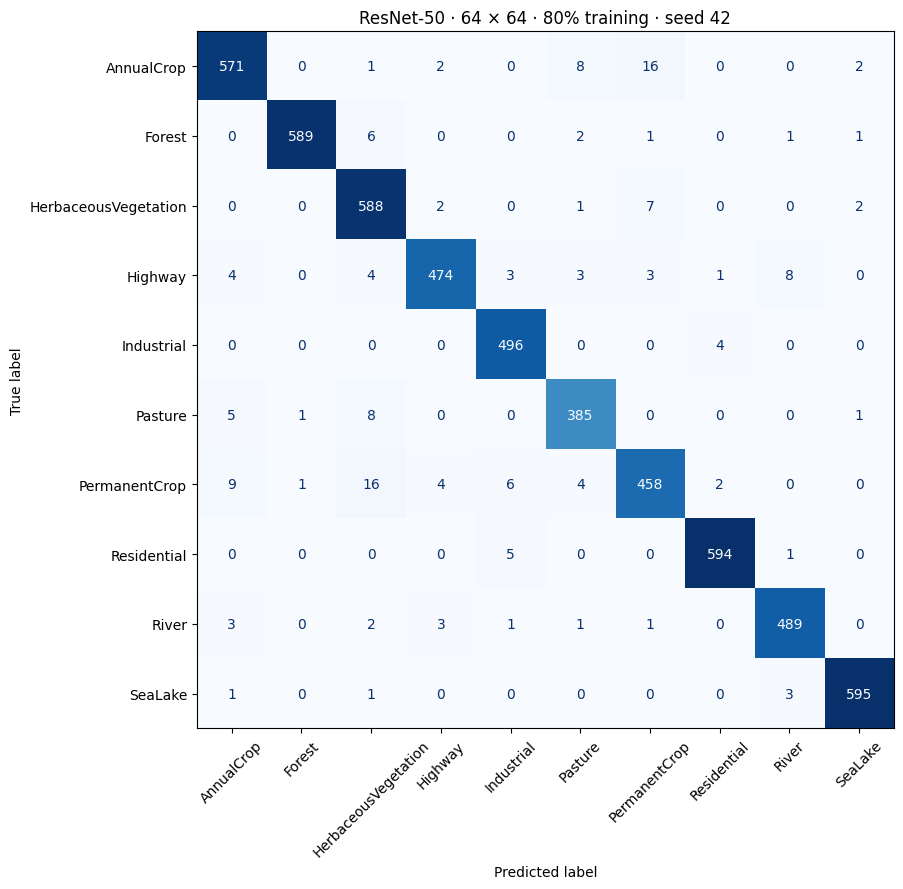

In [27]:
# Load the saved predictions and plot the confusion matrix
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

RESULTS_DIR = Path(
    "/content/drive/MyDrive/EuroSAT/results/"
    "resnet50_64_full80_20261103_161457"
)

pred = pd.read_csv(RESULTS_DIR / "test_predictions.csv")

with open(RESULTS_DIR / "class_to_idx.json") as f:
    class_to_idx = json.load(f)

class_names = sorted(class_to_idx, key=class_to_idx.get)
class_ids = [class_to_idx[name] for name in class_names]

cm = confusion_matrix(
    pred["class_idx"],
    pred["predicted_class_idx"],
    labels=class_ids
)

fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues")

ax.set_title("ResNet-50 · 64 × 64 · 80% training · seed 42")
plt.tight_layout()
fig.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

pd.DataFrame(
    cm, index=class_names, columns=class_names
).to_csv(RESULTS_DIR / "confusion_matrix.csv")

River predicted as Highway: 3
Highway predicted as River: 8


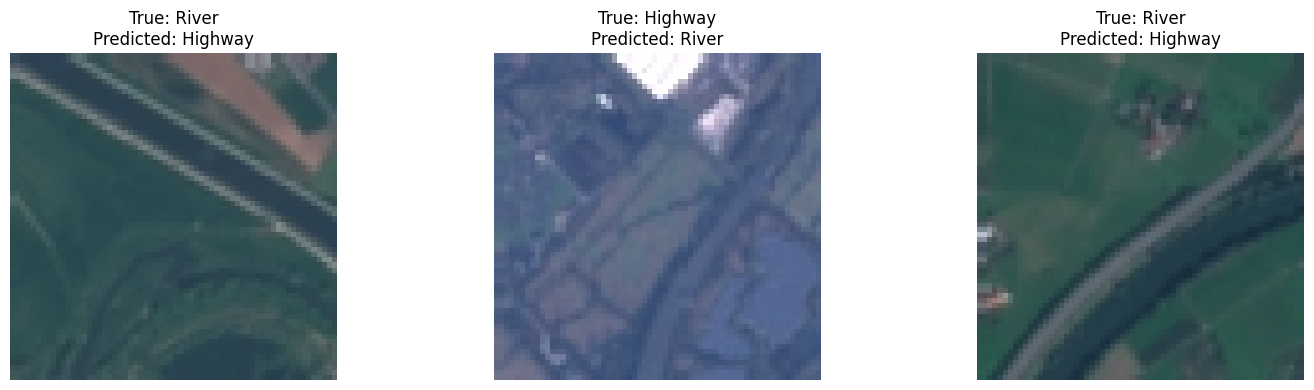

In [28]:
# Show up to three river/highway mistakes
from PIL import Image

river = class_to_idx["River"]
highway = class_to_idx["Highway"]
idx_to_class = {v: k for k, v in class_to_idx.items()}

river_as_highway = pred[
    (pred["class_idx"] == river)
    & (pred["predicted_class_idx"] == highway)
]

highway_as_river = pred[
    (pred["class_idx"] == highway)
    & (pred["predicted_class_idx"] == river)
]

print("River predicted as Highway:", len(river_as_highway))
print("Highway predicted as River:", len(highway_as_river))

# Include one example from each direction, where available,
# then fill the remaining positions without duplicates.
all_errors = pd.concat([river_as_highway, highway_as_river])
examples = pd.concat([
    river_as_highway.head(1),
    highway_as_river.head(1),
    all_errors
]).drop_duplicates("relative_path").head(3)

examples.to_csv(
    RESULTS_DIR / "river_highway_examples.csv", index=False
)

if examples.empty:
    print("No River/Highway confusions occurred in this run.")
else:
    fig, axes = plt.subplots(
        1, len(examples),
        figsize=(5 * len(examples), 4),
        squeeze=False
    )

    for ax, (_, row) in zip(axes[0], examples.iterrows()):
        image_path = Path(DATASET_DIR) / row["relative_path"]

        with Image.open(image_path) as image:
            ax.imshow(image.convert("RGB"))

        actual = idx_to_class[int(row["class_idx"])]
        predicted = idx_to_class[int(row["predicted_class_idx"])]

        ax.set_title(f"True: {actual}\nPredicted: {predicted}")
        ax.axis("off")

    plt.tight_layout()
    fig.savefig(
        RESULTS_DIR / "river_highway_examples.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()